# Figure 5: Mixed vs. Blocked SNR

Translation of `Figure05_mixedVsBlockedSNR.m`; bounds from the trial-level stopping model (2026-10-10).

## What this notebook does

Compares how participants' decision bounds relate to SNR in two task variants:

- **OL (Blocked SNR)**: Each block contains only one SNR level; subjects know which SNR applies.
- **MX (Mixed SNR)**: Multiple SNR levels are interleaved within a block; subjects must infer the SNR.

The hypothesis: in mixed SNR, subjects cannot set SNR-specific bounds, so low-SNR and high-SNR
bounds should be more similar than in blocked SNR.

**Figure** — 2 rows (OL / MX) × 3 columns (blocks 1–3):
Reward-rate heatmap (coins per trial vs. lo × hi SNR bound pair, simulated with fixed bounds —
the optimal policy), with per-subject bound plateaus overlaid as open circles (open
squares: clamped at the panel edge, plateau > 0.78; gray crosses at the edge: a plateau at a fit
limit, left out of the statistics and the median). The near-optimal region (≥ 95 % of max RR) is outlined with a thin
blue contour (no single optimum is marked: the surfaces are nearly flat near their peak, so the
best grid cell is not stable across simulation runs); a large filled red circle marks the median
of the participant data. Both are drawn above the per-subject scatter. Each panel's lower-right corner reports
the paired lo/hi bound statistics: median(hi - lo) and its Wilcoxon signed-rank p-value (median
!= 0), and the Spearman correlation between lo and hi with its p-value (correlation != 0).

**Bounds**: the stopping model's bound plateau (`pigeon.stopping`, notebook
`Test_stoppingModel`; fits by `scripts/run_stopping_fits.py`, cached in `data/processed/`).
- OL: `stopping_fits_main.pkl`; low SNR = raw block b, high SNR = raw block b + 3 (each block
  is a single SNR).
- MX: `stopping_fits_mx_by_snr.pkl`, the same model with every per-block parameter separate for
  the low- and high-SNR trials of each block (groups `B<b>_lo`, `B<b>_hi`). A separate bound
  per SNR fits MX worse than one bound per block (model comparison in `Test_stoppingModel`),
  but it is what this figure compares.

**Plateau at a fit limit** (`get_plateau_at_limit`, 0.002 or 2.0): no evidence-based stopping
(random responding or committing on any movement). A subject whose low- or high-SNR plateau is at
a limit is left out of that panel's statistics and median (counts printed).

Fits use the stopping model's trial selection (`get_stopping_model_trials`: trial_number ≥
max(10, ceil τ), no DT cutoff, no wall-hit exclusion, raw positions).

## Imports

Standard scientific Python libraries plus `get_data_table`, the cached stopping-model fits, and
`get_simulated_data_table`. No data loading or analysis here.

## Load data

Loads both task variants:
- `data_table_mx`: Mixed-SNR (MX) task — multiple SNR levels interleaved within each block.
- `data_table_ol`: Online / Blocked-SNR (OL) task — one SNR level per block.

Both calls apply internal processing: bound/DT computation, wall-hit marking, bias correction,
and block merging (6 → 3 blocks). No trials are dropped at this stage.

## Parameters and RR-matrix computation

**`BLOCKS`**: All three blocks analyzed: block 1 (gain only), block 2 (coin penalty for errors),
block 3 (step loss for errors).

**`RR_BOUNDS`**: Bound grid for the reward-rate simulation (0.01 to 0.81 in steps of 0.05, 17
values; MATLAB used `rrBounds = 0.01:0.05:0.76`, extended here to the panel edge).

**`NUM_RR_REPS`**: Number of simulated subjects per condition (matching MATLAB `numRRReps=100`).

**`G_MEANS`**: Generative means for lo and hi SNR (matching MATLAB defaults `[0.05 0.15]`).

**`COMPUTE_RR`**: Set to `False` to skip the slow simulation and show only the scatter overlay.
The simulation takes ~1 min per block for OL and ~15 min per block for MX.

**`rr_matrices`**: Dict keyed by `(task_type, block)`. Both OL and MX are stored as
`rr_matrix[hi_idx, lo_idx]` so `imshow(origin='lower')` places lo-SNR bound on the x-axis and
hi-SNR bound on the y-axis, matching the scatter overlay and axis labels.

**Bounds** (`fit_bounds`, keyed by `(task_type, block)`): per-subject bound plateau
for the low- and high-SNR condition (see top), and `fit_limit[(task_type, block)]`, True where
either plateau is at a fit limit. Subjects without both fits are left out of a panel.

In [1]:
import sys
sys.path.insert(0, '..')

import numpy as np
import matplotlib.pyplot as plt
import scipy.stats
import pandas as pd
from pathlib import Path

from pigeon.data import get_data_table
from pigeon.simulation import get_simulated_data_table
from pigeon.stopping import get_plateau_at_limit
from pigeon.pathDefaults import FIGURES_DIR
from pigeon.plotting import FONT_RC, add_panel_label, CONDITION_LABELS, TASK_ROW_LABELS

In [2]:
data_table_mx = get_data_table(task_type='MX')
data_table_ol = get_data_table(task_type='OL')

# Bound plateaus, low and high SNR, per subject: fit_bounds[(task, block)] = (lo, hi); fit_limit marks
# subjects with either plateau at a fit limit (left out of the statistics).
PROCESSED = Path('../data/processed')
_ol = pd.read_pickle(PROCESSED / 'stopping_fits_main.pkl').query("task == 'OL'").copy()
_mx = pd.read_pickle(PROCESSED / 'stopping_fits_mx_by_snr.pkl').query("task == 'MX'").copy()
for _f in (_ol, _mx):
    _f['at_limit'] = get_plateau_at_limit(_f)
_scale = {'OL': _ol.pivot(index='subject_index', columns='group', values='bound_scale'),
          'MX': _mx.pivot(index='subject_index', columns='group', values='bound_scale')}
_lim = {'OL': _ol.pivot(index='subject_index', columns='group', values='at_limit').fillna(False).astype(bool),
        'MX': _mx.pivot(index='subject_index', columns='group', values='at_limit').fillna(False).astype(bool)}
fit_limit = {}
_groups = {'OL': lambda b: (f'B{b}', f'B{b + 3}'), 'MX': lambda b: (f'B{b}_lo', f'B{b}_hi')}
fit_bounds = {}
for _task in ('OL', 'MX'):
    for _b in (1, 2, 3):
        _lo, _hi = _groups[_task](_b)
        fit_bounds[(_task, _b)] = (_scale[_task][_lo].to_numpy(), _scale[_task][_hi].to_numpy())
        fit_limit[(_task, _b)] = (_lim[_task][_lo] | _lim[_task][_hi]).reindex(_scale[_task].index).to_numpy()
        _both = np.isfinite(fit_bounds[(_task, _b)][0]) & np.isfinite(fit_bounds[(_task, _b)][1])
        print(f'{_task} block {_b}: {_both.sum()} subjects with both fits; {np.sum(_both & fit_limit[(_task, _b)])} '
              f'left out (a plateau at a fit limit): {list(_scale[_task].index[_both & fit_limit[(_task, _b)]])}')

OL block 1: 60 subjects with both fits; 7 left out (a plateau at a fit limit): [4, 5, 16, 51, 58, 59, 60]
OL block 2: 60 subjects with both fits; 2 left out (a plateau at a fit limit): [13, 51]
OL block 3: 59 subjects with both fits; 3 left out (a plateau at a fit limit): [13, 44, 51]
MX block 1: 60 subjects with both fits; 2 left out (a plateau at a fit limit): [18, 45]
MX block 2: 60 subjects with both fits; 3 left out (a plateau at a fit limit): [18, 53, 54]
MX block 3: 60 subjects with both fits; 4 left out (a plateau at a fit limit): [18, 27, 28, 42]


In [3]:
# ── Parameters ────────────────────────────────────────────────────────────────
BLOCKS      = [1, 2, 3]                     # all three task blocks
RR_BOUNDS   = np.arange(0.01, 0.82, 0.05)  # bound grid: 0.01:0.05:0.81 (17 values; to the panel edge)
NUM_RR_REPS = 300                           # simulated subjects per RR computation (RR surfaces are flat
                                            # near the peak, so the optimum needs more than MATLAB's 100)
G_MEANS     = [0.05, 0.15]                 # lo and hi SNR generative means
COMPUTE_RR  = True                          # False = skip slow simulation
X_SHOW_MAX  = 0.78                          # fitted bounds above this are clamped to the panel edge

rng = np.random.default_rng(42)


# ── Helper: simulate reward-rate matrix ───────────────────────────────────────
def compute_rr_matrix(task_type, block, rr_bounds, num_reps, g_means, rng):
    """Compute expected reward rate over a lo-SNR-bound × hi-SNR-bound grid.

    Both OL and MX return rr_matrix[hi_idx, lo_idx] so that imshow(origin='lower')
    displays the matrix with lo-SNR bound on the x-axis and hi-SNR bound on the
    y-axis, matching the scatter overlay and axis labels.

    For OL (blocked SNR): lo and hi SNR blocks are simulated separately for each
    bound value. Their mean coin counts are added, matching MATLAB's accumulation:
        RRMatrix_(:, b1) += mean(loCoinCounts)   [column b1 = lo-bound]
        RRMatrix_(b1, :) += mean(hiCoinCounts)   [row b1 = hi-bound]
    → rr_matrix[hi_idx, lo_idx]

    For MX (mixed SNR): each (lo_bound, hi_bound) pair requires its own
    simulation with both SNR levels interleaved (equivalent to MATLAB's
    boundType='varBySNR'). Stored as rr_matrix[hi_idx, lo_idx] to match OL.
    """
    n = len(rr_bounds)
    rr_matrix = np.zeros((n, n))
    specs = {'num_subjects': num_reps, 'blocks': [block]}

    if task_type == 'OL':
        for b1, bnd in enumerate(rr_bounds):
            print(f'  OL block {block} RR matrix: bound {b1 + 1}/{n}', end='\r')

            lo_table = get_simulated_data_table(
                specs=specs, generative_mean=g_means[0],
                bound_mean=bnd, correct_bias=None, rng=rng)
            lo_coins = lo_table.groupby('subject_index')['coin_count'].last().mean()

            hi_table = get_simulated_data_table(
                specs=specs, generative_mean=g_means[1],
                bound_mean=bnd, correct_bias=None, rng=rng)
            hi_coins = hi_table.groupby('subject_index')['coin_count'].last().mean()

            rr_matrix[:, b1] += lo_coins
            rr_matrix[b1, :] += hi_coins

    else:  # MX — stored as rr_matrix[hi_idx, lo_idx] to match OL display convention
        for b1, lo_bnd in enumerate(rr_bounds):
            print(f'  MX block {block} RR matrix: lo-bound {b1 + 1}/{n}', end='\r')
            for b2, hi_bnd in enumerate(rr_bounds):
                mx_table = get_simulated_data_table(
                    specs=specs,
                    generative_mean=list(g_means),
                    bound_mean=[lo_bnd, hi_bnd],
                    correct_bias=None, rng=rng)
                rr_matrix[b2, b1] = (
                    mx_table.groupby('subject_index')['coin_count'].last().mean())
    print()
    return rr_matrix


def _fmt_p(p):
    return '<0.001' if p < 0.001 else f'{p:.3f}'


# ── Helper: heatmap + scatter panel ───────────────────────────────────────────
def _plot_heatmap_panel(ax, lo, hi, rr_bounds, rr_matrix, vmax=None, lim=None):
    """Lo × hi SNR bound heatmap with subject scatter (lo, hi: per-subject bound plateaus; lim: True
    where either plateau is at a fit limit, drawn as gray crosses and left out of the statistics).

    Returns the `AxesImage` from `imshow` (or `None` if no RR matrix was
    available) so callers can build a shared colorbar from it. If `vmax` is
    given, it sets the color scale (use a value shared across panels for a
    comparable colorbar); otherwise each panel is normalized to its own max.

    Annotates the panel's lower-right corner with the paired lo/hi bound
    statistics: median(hi - lo) and its Wilcoxon signed-rank p-value
    (median != 0) on the top line, and the Spearman correlation between lo
    and hi with its p-value (correlation != 0) on the bottom line.
    """
    b_min, b_max = rr_bounds[0], rr_bounds[-1]

    im = None
    if rr_matrix is not None:
        panel_vmax = rr_matrix.max() if vmax is None else vmax
        im = ax.imshow(
            rr_matrix, origin='lower',
            extent=[b_min - 0.025, b_max + 0.025, b_min - 0.025, b_max + 0.025],
            aspect='auto', vmin=0, vmax=panel_vmax, cmap='viridis', zorder=0)

    ax.plot([0, 0.75], [0, 0.75], 'k:', linewidth=1, zorder=1)

    both = np.isfinite(lo) & np.isfinite(hi)
    lim = np.zeros(len(lo), bool) if lim is None else lim
    valid = both & ~lim
    # Plateau at a fit limit: gray crosses at the clamped position, left out of everything else.
    ax.plot(np.clip(lo[both & lim], 0, X_SHOW_MAX), np.clip(hi[both & lim], 0, X_SHOW_MAX), 'x', color='0.55',
            markersize=7, markeredgewidth=1.5, zorder=2, clip_on=False)
    # Fitted bounds beyond the panel (> X_SHOW_MAX; beyond the wall at 0.75 means commits are
    # essentially all guesses) are clamped to the edge and drawn as open squares.
    clamped = valid & ((lo > X_SHOW_MAX) | (hi > X_SHOW_MAX))
    lo_s, hi_s = np.minimum(lo, X_SHOW_MAX), np.minimum(hi, X_SHOW_MAX)
    ax.plot(lo_s[valid & ~clamped], hi_s[valid & ~clamped], 'ko', markerfacecolor='white',
            markersize=8, markeredgewidth=1.5, zorder=2)
    ax.plot(lo_s[clamped], hi_s[clamped], 'ks', markerfacecolor='white',
            markersize=7, markeredgewidth=1.5, zorder=2, clip_on=False)

    if rr_matrix is not None:
        # RR-landscape summary is drawn last (above the participant scatter) so
        # it isn't obscured by the data points. The near-optimal (>=95% of max
        # RR) region is outlined with a thin blue contour. No single peak is
        # marked: the RR surfaces are nearly flat near their maximum, and the
        # best grid cell moved by up to 0.15 between simulation runs (100 vs. 300
        # subjects per cell), while the near-optimal region is stable. A large filled red circle marks the median
        # of the participant data, for a direct visual comparison between
        # where subjects actually sit and where the RR landscape peaks.
        # (This thresholding always uses the panel's own max, independent of
        # the shared colorbar scale passed via `vmax`.)
        near_opt = rr_matrix >= 0.95 * rr_matrix.max()
        lo_grid, hi_grid = np.meshgrid(rr_bounds, rr_bounds)
        ax.contour(lo_grid, hi_grid, near_opt.astype(float), levels=[0.5],
                   colors='tab:blue', linewidths=1.5, zorder=3)

    if valid.sum():
        ax.plot(np.nanmedian(lo[valid]), np.nanmedian(hi[valid]), 'o', color='red',
                markersize=11, markeredgecolor='k', markeredgewidth=1, zorder=5)

    ax.set_xlim(0, X_SHOW_MAX + 0.02)
    ax.set_ylim(0, X_SHOW_MAX + 0.02)
    ax.set_xticks([0, 0.2, 0.4, 0.6])
    ax.set_yticks([0, 0.2, 0.4, 0.6])
    ax.set_aspect('equal')

    if valid.sum() > 2:
        med = np.median(hi[valid] - lo[valid])
        _, p_diff = scipy.stats.wilcoxon(lo[valid], hi[valid])
        rho, p_rho = scipy.stats.spearmanr(lo[valid], hi[valid])
        annot = (f'median={med:.3f}, p={_fmt_p(p_diff)}\n'
                 f'ρ={rho:.3f}, p={_fmt_p(p_rho)}')
        # Upper left (the emptiest corner in both tasks), drawn beneath the markers.
        ax.text(0.04, 0.90, annot, transform=ax.transAxes, ha='left', va='top',
                fontsize=FS - 4, linespacing=1.4, zorder=1.5,
                bbox=dict(facecolor='white', alpha=0.6, edgecolor='none', pad=1.5))

    return im


# ── Task list ─────────────────────────────────────────────────────────────────
tasks = [
    (data_table_ol, 'OL (Blocked SNR)', 'OL'),
    (data_table_mx, 'MX (Mixed SNR)',   'MX'),
]

# ── Compute RR matrices: keyed by (task_type, block) ─────────────────────────
# Cached in data/processed (the MX matrices take ~45 min per block at 300 subjects); the cache is
# reused only if the grid, subject count, generative means and seed all match.
import pickle
RR_CACHE = Path('../data/processed/Figure05_rr_matrices.pkl')
RR_KEY = dict(bounds=np.round(RR_BOUNDS, 6).tolist(), reps=NUM_RR_REPS, g_means=list(G_MEANS), seed=42)
rr_matrices = {}

if COMPUTE_RR:
    if RR_CACHE.exists() and pickle.load(open(RR_CACHE, 'rb'))['key'] == RR_KEY:
        rr_matrices = pickle.load(open(RR_CACHE, 'rb'))['rr_matrices']
        print(f'Loaded RR matrices from {RR_CACHE}')
    else:
        for _, label, task_type in tasks:
            for block in BLOCKS:
                print(f'Computing RR matrix for {task_type} block {block}...')
                rr_matrices[(task_type, block)] = compute_rr_matrix(
                    task_type, block, RR_BOUNDS, NUM_RR_REPS, G_MEANS, rng)
                print(f'  Done.')
        pickle.dump({'key': RR_KEY, 'rr_matrices': rr_matrices}, open(RR_CACHE, 'wb'))

Loaded RR matrices from ../data/processed/Figure05_rr_matrices.pkl


## Figure

Publication-quality figure at 14 cm wide (≈ 2.4 JNeurosci columns): 2 rows (OL / MX) × 3 columns
(blocks 1–3) of heatmap + scatter panels, each row with its own colorbar to the right. Panel
width = height = 4 cm; gaps 1.0 cm (horizontal) × 1.3 cm (vertical). Block label in column header
(top row); paired lo/hi bound statistics (median difference + Wilcoxon p, Spearman correlation +
p) in each panel's lower-right corner; task-type row label on the left y-axis, shared "High-SNR
bound" / "Low-SNR bound" axis labels centered across rows/columns. Each row's 3 panels share one
reward-rate color scale (normalized to the max across that row's RR matrices); OL and MX use
separate scales since their reward rates aren't on the same footing. Saves to `Figure05.pdf`.

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


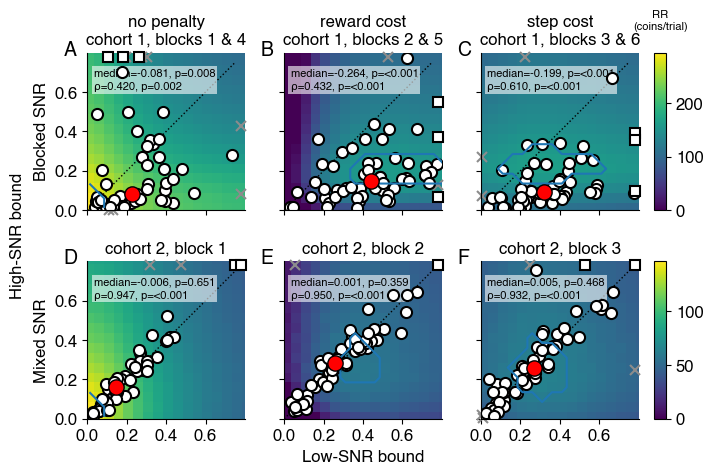

Saved /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Figures/Figure05.pdf (+ .png)


In [4]:
# ── Main figure: 2 rows (OL/MX) × 3 cols (blocks 1–3), heatmap panels ────────
import matplotlib.gridspec as gridspec

CM  = 1 / 2.54
WID = 14.0           # panel-grid width (cm)
HTS = [4.0, 4.0]     # row heights (cm) — matches panel width for square axes
PSH = 1.3            # vertical panel separation (cm)
PSW = 1.0            # horizontal panel separation (cm)
FS  = 12             # font size (pt)
CBAR_W   = 0.3       # colorbar width (cm)
CBAR_PAD = 0.4       # gap between panel grid and colorbar (cm)

n_rows  = len(tasks)
n_cols  = len(BLOCKS)
fig_h   = sum(HTS) + PSH * (n_rows - 1)
panel_w = (WID - PSW * (n_cols - 1)) / n_cols  # = 4.0 cm → square panels

hspace = PSH / np.mean(HTS)
wspace = PSW / panel_w

fig_w = WID + CBAR_PAD + CBAR_W   # total figure width, including colorbar strip

plt.rcParams.update({'font.size': FS, 'axes.labelsize': FS, 'axes.titlesize': FS, **FONT_RC})

fig_main = plt.figure(figsize=(fig_w * CM, fig_h * CM))
panel_right = WID / fig_w   # fraction of total figure width used by the panel grid
gs = gridspec.GridSpec(n_rows, n_cols, figure=fig_main,
                       left=0, right=panel_right, bottom=0, top=1,
                       hspace=hspace, wspace=wspace)
axs = np.array([[fig_main.add_subplot(gs[r, c])
                 for c in range(n_cols)] for r in range(n_rows)])

# Panel headers. Row 0 (cohort 1, blocked SNR): condition name + the two raw
# blocks folded into this merged block (see data.py's blocks 4-6 -> 1-3
# relabeling). Row 1 (cohort 2, mixed SNR): no per-condition names apply there,
# just the cohort/block identity.
ROW_TITLES = {
    0: {b: f'{CONDITION_LABELS[b]}\ncohort 1, blocks {b} & {b + 3}' for b in BLOCKS},
    1: {1: 'cohort 2, block 1', 2: 'cohort 2, block 2', 3: 'cohort 2, block 3'},
}

# Each row (task type) gets its own color scale, shared across that row's 3
# blocks — OL and MX reward rates aren't on the same footing, so a single
# figure-wide scale would wash out one row's structure relative to the other.
row_vmax = {
    row_idx: max((rr_matrices[(task_type, block)].max()
                   for block in BLOCKS if (task_type, block) in rr_matrices),
                  default=None)
    for row_idx, (_, _, task_type) in enumerate(tasks)
}

row_im = {}
for row_idx, (data_table, task_label, task_type) in enumerate(tasks):
    for col_idx, block in enumerate(BLOCKS):
        ax = axs[row_idx, col_idx]
        panel_im = _plot_heatmap_panel(
            ax, *fit_bounds[(task_type, block)], RR_BOUNDS,
            rr_matrices.get((task_type, block)), vmax=row_vmax[row_idx], lim=fit_limit[(task_type, block)])
        if panel_im is not None:
            row_im[row_idx] = panel_im

        ax.set_title(ROW_TITLES[row_idx][block])

        # y-axis: task-type row label only on leftmost column ("High-SNR
        # bound" is added once, centered across both rows, below)
        if col_idx == 0:
            ax.set_ylabel(TASK_ROW_LABELS[task_type])
        else:
            ax.tick_params(axis='y', labelleft=False)

        # x-axis: tick labels on bottom row only ("Low-SNR bound" is added
        # once, centered under the middle column, below)
        if row_idx != n_rows - 1:
            ax.tick_params(axis='x', labelbottom=False)

        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        add_panel_label(ax, chr(65 + row_idx * n_cols + col_idx))

# One colorbar per row, vertically aligned with that row's panels, each on its
# own (row-shared) reward-rate scale.
for row_idx, (_, _, task_type) in enumerate(tasks):
    if row_idx not in row_im:
        continue
    y0, y1 = axs[row_idx, 0].get_position().y0, axs[row_idx, 0].get_position().y1
    cax = fig_main.add_axes([(WID + CBAR_PAD) / fig_w, y0, CBAR_W / fig_w, y1 - y0])
    cbar = fig_main.colorbar(row_im[row_idx], cax=cax)
    if task_type == 'OL':
        cbar.ax.set_title('RR\n(coins/trial)', fontsize=8, pad=17)

# Shared axis labels: "High-SNR bound" centered vertically between the two
# rows (just left of the per-row task-type labels), "Low-SNR bound" centered
# horizontally under the middle column (just below its tick labels).
fig_main.canvas.draw()
renderer = fig_main.canvas.get_renderer()

label_x0 = min(
    axs[0, 0].yaxis.label.get_window_extent(renderer=renderer).x0,
    axs[-1, 0].yaxis.label.get_window_extent(renderer=renderer).x0,
)
label_x_fig = fig_main.transFigure.inverted().transform((label_x0, 0))[0]
row_y0 = axs[-1, 0].get_position().y0
row_y1 = axs[0, 0].get_position().y1
fig_main.text(label_x_fig - 0.015, (row_y0 + row_y1) / 2, 'High-SNR bound',
              rotation=90, ha='right', va='center', fontsize=FS)

mid_col = n_cols // 2
mid_ax = axs[-1, mid_col]
tick_y0 = mid_ax.xaxis.get_tightbbox(renderer).y0
tick_y_fig = fig_main.transFigure.inverted().transform((0, tick_y0))[1]
col_x0, col_x1 = mid_ax.get_position().x0, mid_ax.get_position().x1
fig_main.text((col_x0 + col_x1) / 2, tick_y_fig - 0.015, 'Low-SNR bound',
              ha='center', va='top', fontsize=FS)

out = FIGURES_DIR / 'Figure05.pdf'
fig_main.savefig(out, dpi=300, bbox_inches='tight')
fig_main.savefig(out.with_suffix('.png'), dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved {out} (+ .png)')

## Hi/Lo SNR bound ratio summary

For each condition and block, prints:

1. **Per-participant median [IQR]**: the ratio `hi_bound / lo_bound` computed per subject (using
   the same bound plateaus as the heatmap scatter; plateau-limit subjects left out), summarized as
   median [25th–75th percentile] across subjects.
2. **Near-optimal region**: the range of low- and high-SNR bounds, and of their ratio, over the
   grid cells with reward rate ≥ 95% of the maximum (the blue contour). Requires `COMPUTE_RR = True`.


In [5]:
# ── Hi/Lo SNR bound ratio: per-participant and at optimal RR ──────────────────
print('Ratio of Hi-SNR to Lo-SNR bound\n')

for data_table, label, task_type in tasks:
    print(f'{label}:')
    for block in BLOCKS:
        lo, hi = fit_bounds[(task_type, block)]

        valid = np.isfinite(lo) & np.isfinite(hi) & (lo > 0) & ~fit_limit[(task_type, block)]
        ratio = hi[valid] / lo[valid]

        med      = np.median(ratio)
        q25, q75 = np.percentile(ratio, [25, 75])

        rr_key = (task_type, block)
        if rr_key in rr_matrices:
            rm = rr_matrices[rr_key]
            hi_idx, lo_idx = np.nonzero(rm >= 0.95 * rm.max())
            lo_r, hi_r = RR_BOUNDS[lo_idx], RR_BOUNDS[hi_idx]
            ratio_r = hi_r / lo_r
            rr_str = (f'lo {lo_r.min():.2f}-{lo_r.max():.2f}, hi {hi_r.min():.2f}-{hi_r.max():.2f}, '
                      f'ratio {ratio_r.min():.2f}-{ratio_r.max():.2f}')
        else:
            rr_str = 'not available (COMPUTE_RR=False)'

        print(f'  Block {block}:  median [IQR] = {med:.3f} [{q25:.3f}, {q75:.3f}];'
              f'  near-optimal (>=95% max RR): {rr_str}')
    print()

Ratio of Hi-SNR to Lo-SNR bound

OL (Blocked SNR):
  Block 1:  median [IQR] = 0.390 [0.185, 1.014];  near-optimal (>=95% max RR): lo 0.01-0.06, hi 0.01-0.11, ratio 0.17-11.00
  Block 2:  median [IQR] = 0.337 [0.238, 0.529];  near-optimal (>=95% max RR): lo 0.36-0.81, hi 0.16-0.26, ratio 0.20-0.63
  Block 3:  median [IQR] = 0.280 [0.171, 0.521];  near-optimal (>=95% max RR): lo 0.11-0.61, hi 0.16-0.31, ratio 0.34-1.91

MX (Mixed SNR):
  Block 1:  median [IQR] = 0.967 [0.843, 1.148];  near-optimal (>=95% max RR): lo 0.01-0.06, hi 0.01-0.11, ratio 0.17-11.00
  Block 2:  median [IQR] = 1.002 [0.897, 1.139];  near-optimal (>=95% max RR): lo 0.31-0.46, hi 0.21-0.41, ratio 0.46-1.14
  Block 3:  median [IQR] = 1.049 [0.848, 1.186];  near-optimal (>=95% max RR): lo 0.16-0.41, hi 0.11-0.41, ratio 0.35-1.62



## Panel-by-panel bound statistics

For each panel (same paired lo/hi per-subject bound plateaus used in the figure's scatter (plateau-limit subjects left out) and
Wilcoxon annotation):

- **Median [IQR] difference**: `hi_bound - lo_bound` per subject, summarized as median
  [25th-75th percentile], with the Wilcoxon signed-rank p-value for median difference != 0
  (identical test/data to the p-value annotated in each panel).
- **Spearman correlation**: rank correlation between each subject's lo and hi bound, with the
  p-value for correlation != 0.

In [6]:
# ── Panel-by-panel bound statistics: diff (hi - lo) and Spearman(lo, hi) ──────
import pandas as pd


def _fmt_p(p):
    return '<0.001' if p < 0.001 else f'{p:.3f}'


stats_rows = []
for row_idx, (data_table, label, task_type) in enumerate(tasks):
    for col_idx, block in enumerate(BLOCKS):
        lo, hi = fit_bounds[(task_type, block)]
        valid = np.isfinite(lo) & np.isfinite(hi) & ~fit_limit[(task_type, block)]
        lo, hi = lo[valid], hi[valid]
        diff = hi - lo

        med, q25, q75 = np.median(diff), *np.percentile(diff, [25, 75])
        _, p_diff = scipy.stats.wilcoxon(lo, hi)
        rho, p_rho = scipy.stats.spearmanr(lo, hi)

        stats_rows.append({
            'Panel': chr(65 + row_idx * n_cols + col_idx),
            'Task': label,
            'Block': block,
            'n': valid.sum(),
            'Median diff [IQR]': f'{med:.3f} [{q25:.3f}, {q75:.3f}]',
            'p (diff != 0)': _fmt_p(p_diff),
            'Spearman r': f'{rho:.3f}',
            'p (r != 0)': _fmt_p(p_rho),
        })

stats_table = pd.DataFrame(stats_rows)
stats_table

,Panel,Task,Block,n,Median diff [IQR],p (diff != 0),Spearman r,p (r != 0)
0,A,OL (Blocked SNR),1,53,"-0.081 [-0.188, 0.003]",0.008,0.420,0.002
1,B,OL (Blocked SNR),2,58,"-0.264 [-0.445, -0.126]",<0.001,0.432,<0.001
2,C,OL (Blocked SNR),3,56,"-0.199 [-0.317, -0.098]",<0.001,0.610,<0.001
3,D,MX (Mixed SNR),1,58,"-0.006 [-0.021, 0.027]",0.651,0.947,<0.001
4,E,MX (Mixed SNR),2,57,"0.001 [-0.027, 0.038]",0.359,0.950,<0.001
5,F,MX (Mixed SNR),3,56,"0.005 [-0.034, 0.039]",0.468,0.932,<0.001
